#**Agrupamiento de Geometrías Complejas: Un Enfoque Basado en Densidad con DBSCAN**

**Autor:** Karen Tatiana Salazar Sepúlveda

**Fecha:** 19/10/2025

**Contexto:** Desarrollado durante el segundo semestre de la Maestría en Ciencia de Datos de la Universidad Autónoma de Bucaramanga - UNAB

## **1. Introducción**
En el ámbito de la analítica de datos y el aprendizaje automático no supervisado, el descubrimiento de patrones latentes dentro de conjuntos de datos no etiquetados representa uno de los desafíos más significativos. Frecuentemente se recurre a técnicas clásicas de agrupamiento (clustering) basadas en centroides, como es el caso del algoritmo K-Means; sin embargo, estas aproximaciones parten de la premisa implícita de que las agrupaciones poseen formas esféricas, convexas y de densidad uniforme, lo cual limita severamente su desempeño frente a geometrías complejas (Han et al., 2011).

El objetivo de este trabajo es aplicar e interpretar el algoritmo DBSCAN (Density-Based Spatial Clustering of Applications with Noise) sobre el conjunto de datos multiforma.csv. A través de un Análisis Exploratorio de Datos (EDA) previo, el escalado de variables y la evaluación iterativa de hiperparámetros (eps y min_samples), se busca identificar estructuras complejas continuas y gestionar adecuadamente la presencia de valores atípicos.

## **2. Análisis Exploratorio de Datos**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.metrics import silhouette_samples
from scipy.spatial.distance import cdist

In [ ]:
# Enlace directo al archivo CSV
url = "https://raw.githubusercontent.com/adiacla/bigdata/refs/heads/master/multiforma.csv"

# Cargar los datos en un DataFrame
df = pd.read_csv(url)

# Mostrar las primeras filas
df.head()

,x,y
0,-0.803739,-0.853053
1,0.852851,0.367618
2,0.927180,-0.274902
3,-0.752626,-0.511565
4,0.706846,0.810679


In [ ]:
print("--- 1. Vista preliminar de los datos ---")
print(df.head())

print("\n--- 2. Dimensión del conjunto de datos ---")
print(f"Filas: {df.shape[0]}, Columnas: {df.shape[1]}")

print("\n--- 3. Información general y tipos de datos ---")
print(df.info())

print("\n--- 4. Verificación de datos faltantes (Nulos) ---")
print(df.isnull().sum())

print("\n--- 5. Estadísticas Descriptivas ---")
print(df.describe())

--- 1. Vista preliminar de los datos ---
          x         y
0 -0.803739 -0.853053
1  0.852851  0.367618
2  0.927180 -0.274902
3 -0.752626 -0.511565
4  0.706846  0.810679

--- 2. Dimensión del conjunto de datos ---
Filas: 1100, Columnas: 2

--- 3. Información general y tipos de datos ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1100 entries, 0 to 1099
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x       1100 non-null   float64
 1   y       1100 non-null   float64
dtypes: float64(2)
memory usage: 17.3 KB
None

--- 4. Verificación de datos faltantes (Nulos) ---
x    0
y    0
dtype: int64

--- 5. Estadísticas Descriptivas ---
                 x            y
count  1100.000000  1100.000000
mean     -0.081222    -0.625431
std       0.644967     1.176170
min      -1.489180    -3.353462
25%      -0.478839    -1.126752
50%      -0.132920    -0.297040
75%       0.366072     0.250817
max       1.492208     1.253874


In [ ]:
# Verificación de filas duplicadas
print("Filas duplicadas:", df.duplicated().sum())


Filas duplicadas: 0


Antes de proceder con el modelado algorítmico, se llevó a cabo un Análisis Exploratorio de Datos, orientado a comprender la naturaleza, calidad y comportamiento de la información fuente. La inspección estructural del dataset reveló que está compuesto por dos variables continuas, denominadas $X$ e $Y$, las cuales corresponden a coordenadas cartesianas dentro de un plano bidimensional. Durante la revisión de la calidad del dato, se constató la ausencia total de registros nulos o faltantes (NaN), así como la inexistencia de filas duplicadas que pudiesen sesgar los cálculos de proximidad.

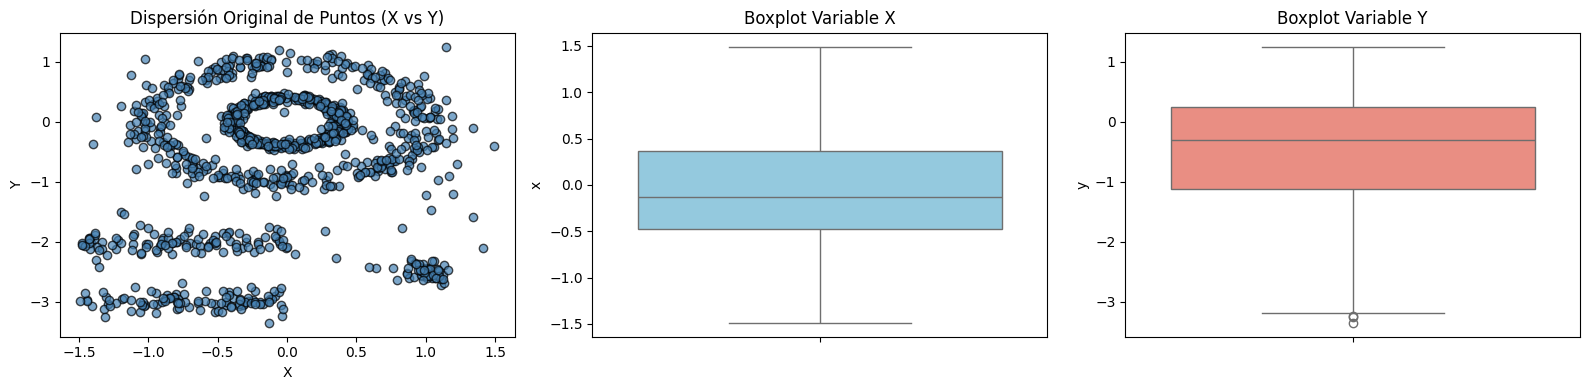

In [ ]:
# Definir variables de columna
col_x = 'x'
col_y = 'y'

# Visualización inicial de la distribución (Diagramas de caja y dispersión inicial)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Scatter plot inicial sin etiquetar
axes[0].scatter(df[col_x], df[col_y], alpha=0.7, c='steelblue', edgecolors='k')
axes[0].set_title('Dispersión Original de Puntos (X vs Y)')
axes[0].set_xlabel('X')
axes[0].set_ylabel('Y')

# Boxplot para detectar atípicos en X
sns.boxplot(y=df[col_x], ax=axes[1], color='skyblue')
axes[1].set_title('Boxplot Variable X')

# Boxplot para detectar atípicos en Y
sns.boxplot(y=df[col_y], ax=axes[2], color='salmon')
axes[2].set_title('Boxplot Variable Y')

plt.tight_layout()
plt.show()

Los diagramas de caja revelaron que la variable $X$ cuenta con una distribución simétrica sin atípicos unidimensionales, mientras que la variable $Y$ insinúa la existencia de valores alejados en su extremo inferior.

Sin embargo, la evaluación del gráfico de dispersión bidimensional aclaró la verdadera naturaleza del problema: los datos forman estructuras complejas no esféricas compuestas por dos anillos concéntricos en la zona superior, dos franjas horizontales en la región inferior y un aglomerado denso en la esquina inferior derecha. Asimismo, el gráfico de dispersión evidencia la presencia de observaciones aisladas y con baja densidad espacial distribuidas en la periferia.

Esta configuración confirma que los puntos alejados detectados en el boxplot de $Y$ forman parte de la arquitectura continua inferior y no son errores, mientras que los puntos verdaderamente atípicos son aquellos dispersos en el espacio intermedio. Este hallazgo justifica el uso de DBSCAN para delimitar con exactitud las agrupaciones de forma arbitraria y aislar el ruido espacial sin imponer una forma predefinida a los grupos.

## **3. Preprocesamiento**

En primera instancia, debido a que el algoritmo DBSCAN basa su funcionamiento en la medición de distancias euclídeas para definir el vecindario entre elementos, se aplicó un proceso de estandarización sobre las variables $X$ e $Y$ empleando el transformador StandardScaler (Pedregosa et al., 2011). Este procedimiento convierte los datos a una escala común con media igual a cero y desviación estándar igual a uno, evitando que una de las dimensiones domine injustificadamente la métrica de distancia (Schubert et al., 2017). Cabe señalar que, dado que $X$ e $Y$ comparten la misma unidad, la estandarización reescala cada eje con un factor distinto (aproximadamente 1/0.645 para $X$ y 1/1.176 para $Y$, según las desviaciones estándar originales), lo que estira la figura en sentido horizontal respecto al vertical. Por ello, las estructuras circulares, como el anillo exterior (de unos 2.39 × 2.42 unidades en la escala original), se observan como elipses (3.71 × 2.06, véase la sección 4.1) en el espacio escalado, en el cual se interpretan todos los resultados posteriores.

In [ ]:
# Verificar nombres de columnas
col_x = 'x' if 'x' in df.columns else df.columns[0]
col_y = 'y' if 'y' in df.columns else df.columns[1]

# Estandarizar los datos (Media = 0, Desviación Estándar = 1)
scaler = StandardScaler()
data_scaled = scaler.fit_transform(df[[col_x, col_y]])

En segunda instancia, se ejecutó un diseño experimental sistemático mediante un bucle de iteración sobre una grilla de hiperparámetros combinando valores del radio de búsqueda (eps) entre 0.2 y 0.7, y del número mínimo de puntos (min_samples) entre 3 y 6. Para cada una de estas combinaciones, se generaron las representaciones gráficas correspondientes con el fin de evaluar visualmente la capacidad de resolución espacial del modelo.

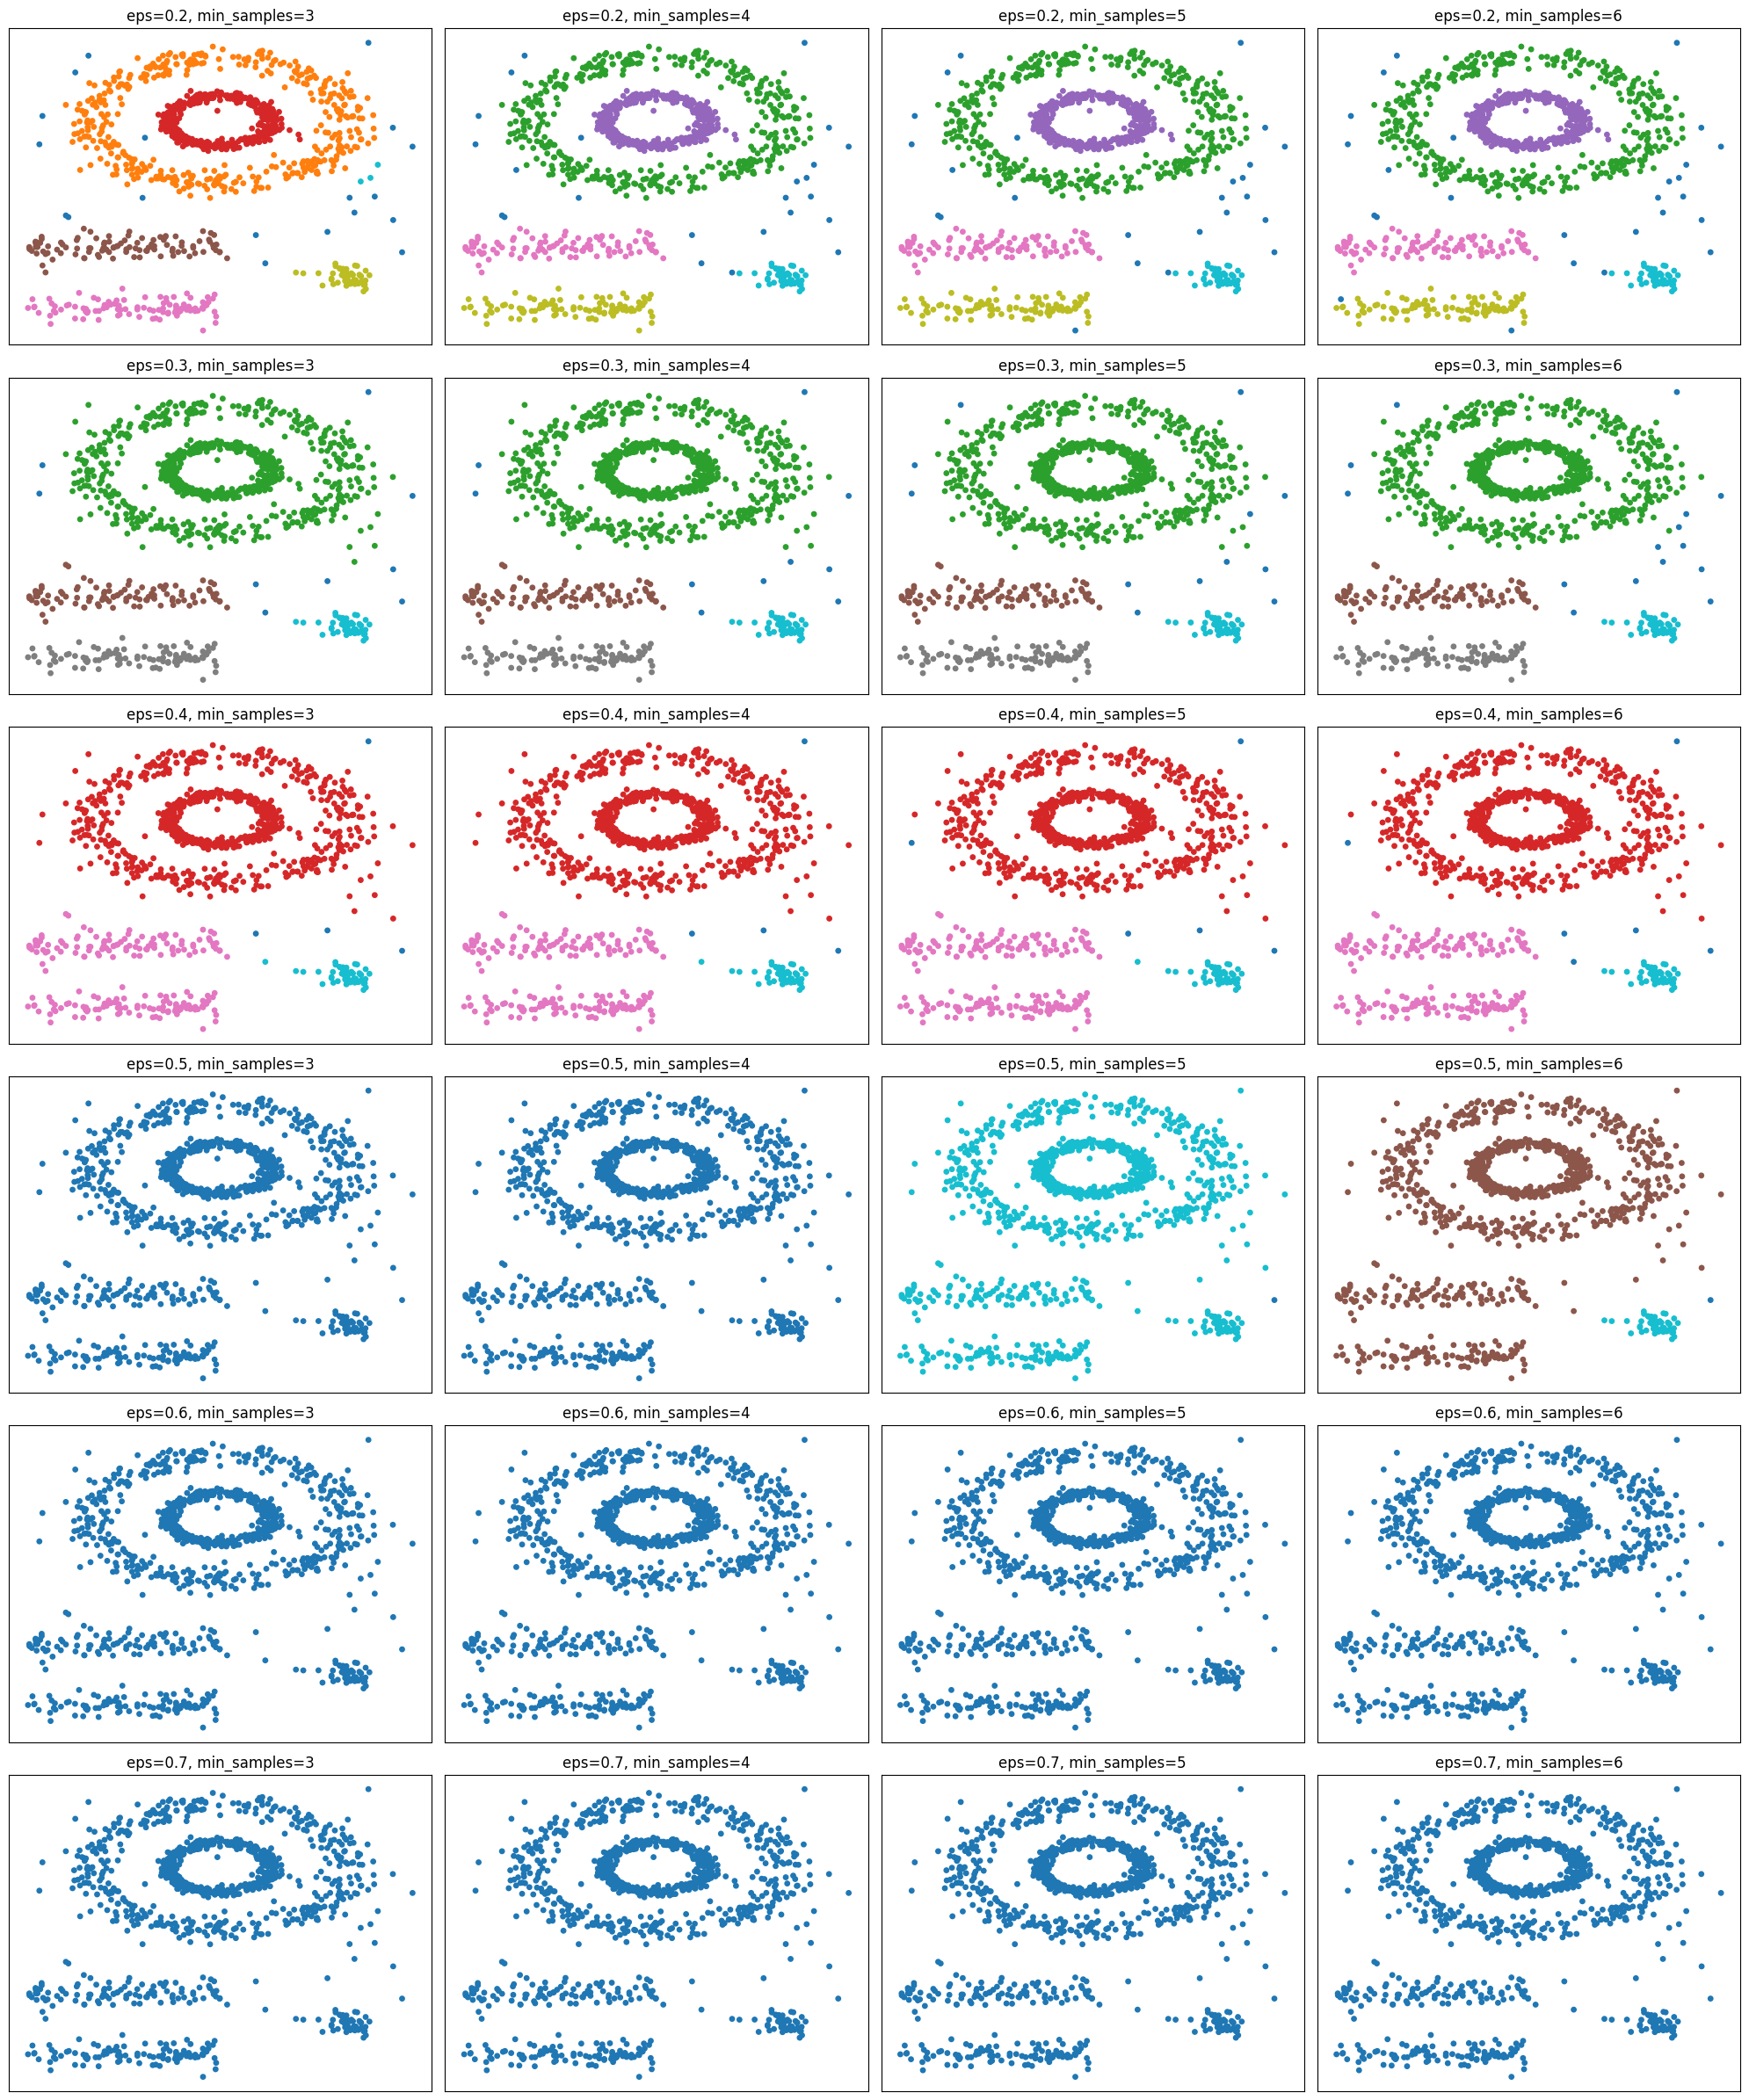

In [ ]:
eps_values = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]
min_samples_values = [3, 4, 5, 6]

# Grilla de subplots (6 filas, 4 columnas)
fig, axes = plt.subplots(6, 4, figsize=(20, 24))

for i, eps in enumerate(eps_values):
    for j, min_samples in enumerate(min_samples_values):
        dbscan = DBSCAN(eps=eps, min_samples=min_samples)
        clusters = dbscan.fit_predict(data_scaled)

        ax = axes[i, j]
        scatter = ax.scatter(data_scaled[:, 0], data_scaled[:, 1], c=clusters, cmap='tab10', s=15)
        ax.set_title(f'eps={eps}, min_samples={min_samples}')
        ax.set_xticks([])
        ax.set_yticks([])

plt.tight_layout()
plt.show()

El análisis visual de la grilla de experimentos evidencia que la segmentación de DBSCAN está determinada principalmente por la sensibilidad del radio de vecindad ($eps$). Con un valor de $eps = 0.2$, el algoritmo demuestra ser, entre los valores evaluados, el único capaz de diferenciar con alta fidelidad las 5 estructuras geométricas independientes del conjunto de datos: los dos anillos concéntricos superiores, las dos franjas horizontales inferiores y el clúster denso inferior derecho. Al incrementar este parámetro, el radio de búsqueda se vuelve excesivamente amplio, lo que provoca que el algoritmo "salte" los espacios vacíos intermedios y fusione de forma indeseada geometrías independientes de manera progresiva: con $eps = 0.3$ se unen los dos anillos concéntricos, con $eps = 0.4$ se une además el par de franjas horizontales, y desde $eps = 0.5$ hasta $0.7$ todo el conjunto colapsa en una única masa uniforme.

Por su parte, el parámetro $min\_samples$ actúa como un filtro de densidad que regula la detección de observaciones atípicas. Manteniendo $eps = 0.2$, se observa que las configuraciones con $min\_samples = 4$, $5$ y $6$ resultan ser soluciones técnicamente viables y equivalentes, ya que las tres logran aislar con éxito las 5 formas geométricas principales. La única diferencia entre estas radica en el grado de rigurosidad frente al ruido: mientras que $min\_samples = 3$ resulta demasiado permisivo al clasificar pequeñas agrupaciones periféricas aisladas como micro-clústeres, los valores de 4 a 6 filtran gradualmente estos puntos diseminados hacia la categoría de ruido (etiqueta $-1$).

Dado que $eps = 0.2$ es el valor más bajo de la grilla, se verificó adicionalmente el comportamiento del modelo con radios menores y cercanos al elegido (0.10 a 0.25, con $min\_samples = 5$). Asimismo, se construyó el gráfico de distancias al k-ésimo vecino más cercano (con k igual a $min\_samples$), que permite orientar la elección de $eps$ a partir de la densidad local de los datos (Ester et al., 1996).


eps=0.10 | clústeres: 30 | ruido: 183 | tamaños: [404, 56, 46, 37, 33, 31, 25, 25, 20, 19, 19, 18, 17, 17, 16, 15, 14, 12, 11, 11, 11, 10, 9, 8, 7, 7, 7, 6, 4, 2]
eps=0.15 | clústeres: 7 | ruido: 47 | tamaños: [406, 232, 103, 97, 91, 75, 49]
eps=0.20 | clústeres: 5 | ruido: 25 | tamaños: [410, 407, 106, 101, 51]
eps=0.25 | clústeres: 4 | ruido: 19 | tamaños: [821, 107, 102, 51]


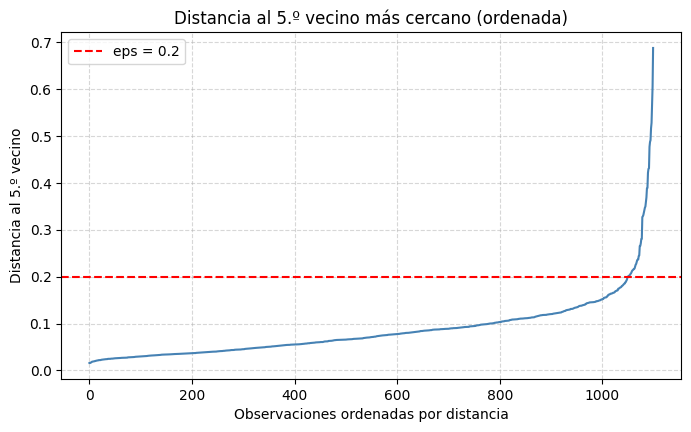

In [ ]:
# Verificación complementaria: valores de eps menores y cercanos al elegido (min_samples = 5)
for eps in [0.10, 0.15, 0.20, 0.25]:
    labels = DBSCAN(eps=eps, min_samples=5).fit_predict(data_scaled)
    tamanos = pd.Series(labels[labels != -1]).value_counts().tolist()
    print(f"eps={eps:.2f} | clústeres: {len(tamanos)} | ruido: {(labels == -1).sum()} | tamaños: {tamanos}")

# Gráfico de distancias al k-ésimo vecino más cercano (k = min_samples = 5)
from sklearn.neighbors import NearestNeighbors
k = 5
distancias, _ = NearestNeighbors(n_neighbors=k).fit(data_scaled).kneighbors(data_scaled)
k_dist = np.sort(distancias[:, -1])

plt.figure(figsize=(8, 4.5))
plt.plot(k_dist, color='steelblue')
plt.axhline(0.2, color='red', ls='--', label='eps = 0.2')
plt.title(f'Distancia al {k}.º vecino más cercano (ordenada)')
plt.xlabel('Observaciones ordenadas por distancia')
plt.ylabel(f'Distancia al {k}.º vecino')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()


La verificación complementaria confirmó que $eps = 0.2$ se ubica en una ventana estrecha de valores adecuados. Con $eps = 0.10$ el algoritmo fragmenta los datos en 30 clústeres y clasifica 183 observaciones como ruido, y con $eps = 0.15$ aún se obtienen 7 clústeres y 47 puntos de ruido, lo que evidencia una sobre-segmentación de las estructuras. Con $eps = 0.20$ se obtienen los cinco clústeres esperados (410, 407, 106, 101 y 51 observaciones) y 25 puntos de ruido. Con $eps = 0.25$, en cambio, los dos anillos ya se fusionan en un único clúster de 821 observaciones, de modo que solo se detectan 4 clústeres y 19 puntos de ruido.

Por su parte, el gráfico de distancias al quinto vecino más cercano muestra un crecimiento lento para la mayoría de las observaciones y un aumento abrupto (codo) en torno a 0.2, correspondiente a los puntos de menor densidad. Dado que el valor $eps = 0.2$ coincide con esa zona de transición, su elección queda respaldada: por debajo de ella las estructuras se fragmentan y por encima se fusionan.


## **4. Selección e identificación del Modelo Óptimo**

El análisis comparativo de la grilla de experimentación ofreció conclusiones determinantes sobre la sensibilidad de los parámetros. Se evidenció que valores de eps más amplios (a partir de 0.25) generan una sobre-agregación, fusionando primero los dos anillos y, con radios mayores, las demás geometrías independientes, mientras que valores menores (0.15 o inferiores) fragmentan las estructuras en múltiples clústeres pequeños. Tras evaluar los compromisos entre sobre-segmentación y fusión, se seleccionó como configuración óptima la combinación de eps = 0.2 y min_samples = 5, por situarse en el rango habitual para datos bidimensionales (Ester et al., 1996, sugieren valores cercanos a 4; Schubert et al., 2017, recomiendan al menos dimensión + 1 y aumentarlo cuando hay ruido) y por reproducir visualmente las cinco estructuras sin fragmentarlas.

Esta elección eliminó los puntos sueltos de los bordes sin deformar la forma de las figuras principales y permitió identificar los 5 clústeres principales del dataset (con 410, 407, 106, 101 y 51 observaciones) junto a 25 puntos clasificados como ruido (-1). Bajo este modelo final, los datos agrupados fueron asignados a sus respectivos clústeres en el DataFrame original, mientras que las observaciones pertenecientes a zonas de baja densidad fueron etiquetadas automáticamente como atípicas.


Cantidad de elementos por clúster:
Cluster
-1     25
 0    410
 1    407
 2    106
 3    101
 4     51
Name: count, dtype: int64


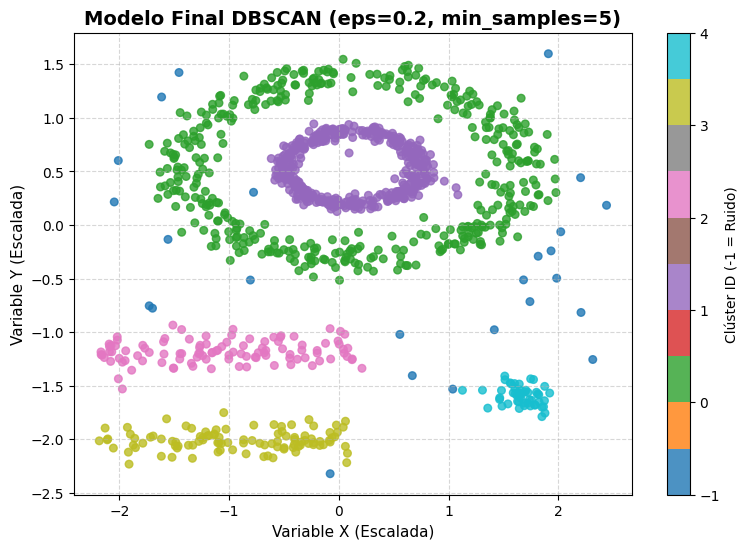

In [ ]:
# Definir los hiperparámetros del modelo final
best_eps = 0.2  # Radio elegido tras la grilla: separa los 5 grupos sin fusionarlos
best_min_samples = 5

# Entrenar el modelo final
dbscan_final = DBSCAN(eps=best_eps, min_samples=best_min_samples)
final_clusters = dbscan_final.fit_predict(data_scaled)

# Asignar al DataFrame
df['Cluster'] = final_clusters

# Verificar la distribución por clúster
print("Cantidad de elementos por clúster:")
print(df['Cluster'].value_counts().sort_index())

# Graficar los resultados
plt.figure(figsize=(9, 6))
scatter = plt.scatter(data_scaled[:, 0], data_scaled[:, 1],
                      c=df['Cluster'],
                      cmap='tab10',
                      s=30,
                      alpha=0.8)

plt.title(f'Modelo Final DBSCAN (eps={best_eps}, min_samples={best_min_samples})', fontsize=14, fontweight='bold')
plt.xlabel('Variable X (Escalada)', fontsize=11)
plt.ylabel('Variable Y (Escalada)', fontsize=11)
plt.colorbar(scatter, label='Clúster ID (-1 = Ruido)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [ ]:
# Filtrar únicamente las observaciones que pertenecen a un clúster (excluyendo el ruido -1)
mask_no_noise = final_clusters != -1
X_clustered = data_scaled[mask_no_noise]
labels_clustered = final_clusters[mask_no_noise]

# Calcular el Silhouette Score
sil_score = silhouette_score(X_clustered, labels_clustered)

# Contar clústeres y ruido
n_clusters = len(set(labels_clustered))
n_noise = list(final_clusters).count(-1)

print(f"Número de clústeres detectados: {n_clusters}")
print(f"Número de puntos clasificados como ruido: {n_noise}")
print(f"Silhouette Score (excluyendo ruido): {sil_score:.4f}")

Número de clústeres detectados: 5
Número de puntos clasificados como ruido: 25
Silhouette Score (excluyendo ruido): 0.2233


Para evaluar cuantitativamente el modelo óptimo ($eps = 0.2$, $min\_samples = 5$) se calculó el coeficiente de Silhouette (Rousseeuw, 1987) sobre las observaciones agrupadas, excluyendo los 25 puntos de ruido (2.3 % del total). Se obtuvo un valor de 0.2233.

Este índice varía entre −1 y 1 y compara, para cada punto, la distancia media a los demás puntos de su propio clúster con la distancia media al clúster vecino más cercano. Un valor de 0.2233 es bajo: en la escala orientativa de Kaufman y Rousseeuw (1990), valores iguales o inferiores a 0.25 indican que no se encuentra una estructura sustancial. Por tanto, este resultado no permite afirmar por sí solo que los grupos estén claramente separados, aunque tampoco implica que el modelo sea deficiente. El índice debe complementarse con el análisis visual y con las características geométricas de los datos, que se desarrollan a continuación.


### **4.1 Análisis complementario del Silhouette: visual y geométrico**

Con el fin de interpretar adecuadamente el valor global, se descompuso el índice por clúster y por observación, y se compararon las distancias entre centroides con las distancias mínimas entre puntos de clústeres distintos.


           n  Silhouette medio  % con s(i) < 0  Ancho X  Alto Y  \
Clúster                                                           
0        410            -0.201           100.0     3.71    2.06   
1        407             0.502             0.0     1.70    0.82   
2        106             0.314             0.0     2.38    0.60   
3        101             0.378             0.0     2.26    0.48   
4         51             0.915             0.0     0.80    0.38   

         Radio medio al centroide  Desv. del radio  
Clúster                                             
0                            1.23             0.28  
1                            0.50             0.12  
2                            0.61             0.36  
3                            0.56             0.31  
4                            0.15             0.10  

Distancia entre centroides:
      0     1     2     3     4
0  0.00  0.02  2.06  2.71  2.60
1  0.02  0.00  2.08  2.73  2.61
2  2.06  2.08  0.00  0.84  2.75
3 

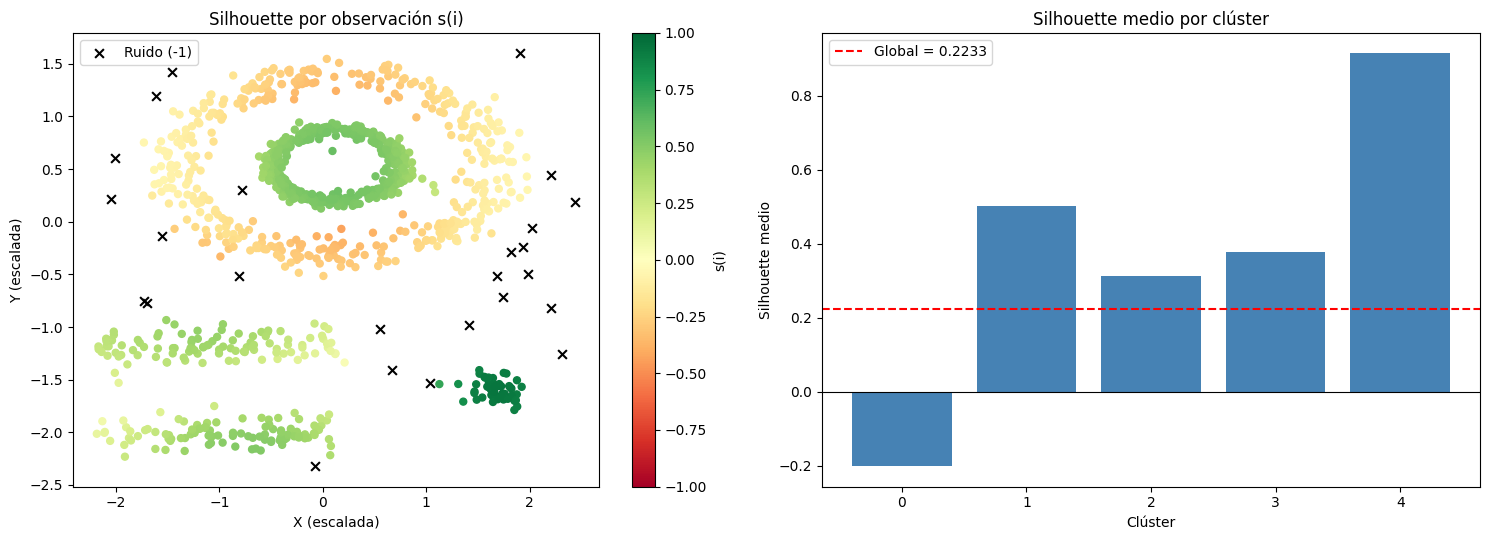

In [ ]:
# Silhouette por observación y por clúster (sin ruido)
sil_i = silhouette_samples(X_clustered, labels_clustered)

resumen = []
for k in sorted(set(labels_clustered)):
    pts = X_clustered[labels_clustered == k]
    s_k = sil_i[labels_clustered == k]
    centroide = pts.mean(axis=0)
    radios = np.linalg.norm(pts - centroide, axis=1)
    resumen.append({
        'Clúster': k,
        'n': len(pts),
        'Silhouette medio': round(s_k.mean(), 3),
        '% con s(i) < 0': round(100 * (s_k < 0).mean(), 1),
        'Ancho X': round(np.ptp(pts[:, 0]), 2),
        'Alto Y': round(np.ptp(pts[:, 1]), 2),
        'Radio medio al centroide': round(radios.mean(), 2),
        'Desv. del radio': round(radios.std(), 2),
    })
resumen = pd.DataFrame(resumen).set_index('Clúster')
print(resumen)

# Distancias entre clústeres: centroides vs. distancia mínima entre puntos ---
ks = sorted(set(labels_clustered))
centroides = np.array([X_clustered[labels_clustered == k].mean(axis=0) for k in ks])
d_centroides = pd.DataFrame(cdist(centroides, centroides), index=ks, columns=ks).round(2)

d_min = pd.DataFrame(index=ks, columns=ks, dtype=float)
for a in ks:
    for b in ks:
        d_min.loc[a, b] = 0.0 if a == b else cdist(
            X_clustered[labels_clustered == a],
            X_clustered[labels_clustered == b]).min()

print("\nDistancia entre centroides:")
print(d_centroides)
print(f"\nDistancia mínima entre puntos de clústeres distintos (eps = {best_eps}):")
print(d_min.round(2))

# Gráficos: puntos coloreados por s(i) y barras por clúster ---
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

sc = axes[0].scatter(X_clustered[:, 0], X_clustered[:, 1], c=sil_i,
                     cmap='RdYlGn', vmin=-1, vmax=1, s=25)
axes[0].scatter(data_scaled[~mask_no_noise, 0], data_scaled[~mask_no_noise, 1],
                c='k', marker='x', s=40, label='Ruido (-1)')
axes[0].set_title('Silhouette por observación s(i)')
axes[0].set_xlabel('X (escalada)')
axes[0].set_ylabel('Y (escalada)')
axes[0].legend()
plt.colorbar(sc, ax=axes[0], label='s(i)')

axes[1].bar(resumen.index.astype(str), resumen['Silhouette medio'], color='steelblue')
axes[1].axhline(sil_score, color='red', ls='--', label=f'Global = {sil_score:.4f}')
axes[1].axhline(0, color='k', lw=0.8)
axes[1].set_title('Silhouette medio por clúster')
axes[1].set_xlabel('Clúster')
axes[1].set_ylabel('Silhouette medio')
axes[1].legend()

plt.tight_layout()
plt.show()


Para facilitar la lectura de los resultados, los clústeres se identifican de la siguiente manera: el clúster 0 corresponde al anillo exterior, el 1 al anillo interior, el 2 a la franja horizontal superior, el 3 a la franja horizontal inferior y el 4 al aglomerado denso de la esquina inferior derecha.

La descomposición del índice por clúster muestra que el valor global de 0.2233 es el promedio de comportamientos muy distintos. El aglomerado denso (clúster 4) alcanza un Silhouette medio de 0.915, coherente con su carácter compacto y aislado, y el anillo interior (clúster 1) obtiene 0.502. Las dos franjas presentan valores intermedios (0.314 y 0.378), pues su forma alargada, con anchos de 2.38 y 2.26 unidades frente a alturas de apenas 0.60 y 0.48, incrementa la distancia media entre puntos de un mismo grupo. En contraste, el anillo exterior (clúster 0) registra un valor medio de −0.201, con el 100 % de sus puntos con s(i) negativo. Este resultado no indica que sus observaciones estén mal asignadas, sino que refleja una limitación de la métrica: el Silhouette se basa en distancias medias, por lo que favorece grupos compactos y convexos. Los dos anillos son concéntricos y sus centroides prácticamente coinciden (distancia de 0.02), de modo que un punto del anillo exterior se encuentra, en promedio, más lejos de los demás puntos de su propio anillo, que rodea al interior, que de los puntos del anillo interior.

La separación entre las estructuras se sustenta, más que en el valor global, en la evidencia visual y geométrica. En el gráfico del modelo final se observan espacios vacíos entre los cinco grupos, y el mapa de colores de s(i) muestra que los valores negativos se concentran de forma uniforme en el anillo exterior y no se dispersan entre los demás clústeres, lo que apunta a un efecto de la forma del grupo y no a una mezcla de observaciones entre ellos. Además, la distancia mínima entre puntos de clústeres distintos es de 0.21 entre los dos anillos, de 0.36 entre las dos franjas y de 0.46 o más en el resto de las parejas. La separación entre los anillos existe, pero es estrecha: resulta solo ligeramente superior al radio $eps = 0.2$, lo que explica por qué con $eps = 0.25$ ya se fusionan en un único clúster de 821 observaciones, tal como se observó en la verificación de la sección 3.

Por su parte, los 25 puntos de ruido fueron excluidos del cálculo, por lo que el índice no evalúa esa decisión. Su clasificación se sustenta en que corresponden a observaciones aisladas, ubicadas en la periferia y en los espacios entre las estructuras, cuya densidad local no alcanza el umbral definido por $eps$ y $min\_samples$.

En síntesis, el valor de 0.2233 debe interpretarse como una limitación del índice frente a geometrías no convexas y no como evidencia, a favor o en contra, de la separación de los grupos. Esta última se respalda en el análisis visual, en las características geométricas de las cinco estructuras (anillos concéntricos, franjas alargadas y aglomerado compacto) y en la comparación entre las distancias mínimas entre clústeres y el radio de vecindad utilizado.


## **5. Conclusión**

La realización de este proyecto permite concluir que el algoritmo DBSCAN constituye una herramienta especialmente adecuada para el análisis de conjuntos de datos con distribuciones espaciales complejas, logrando segmentar estructuras geométricas arbitrarias y no esféricas, tales como los dos anillos concéntricos, las franjas horizontales y el clúster denso inferior derecho.

Asimismo, se evidenció que la definición del radio de densidad (eps) depende de la escala de las métricas de distancia euclidiana, por lo que el escalado de variables (StandardScaler) constituye un paso relevante del preprocesamiento; no obstante, al aplicarse de forma independiente a cada eje modifica la proporción entre ellos, aspecto que debe tenerse presente al interpretar las formas observadas.

La exploración sistemática mediante la grilla de hiperparámetros y la verificación complementaria permitieron evidenciar la alta sensibilidad del algoritmo al radio de vecindad: con eps = 0.25 los dos anillos ya se fusionan, mientras que con eps = 0.15 las estructuras se fragmentan en 7 clústeres. En esa ventana estrecha, la configuración eps = 0.2 y min_samples = 5 permitió identificar las 5 estructuras del dataset (con 410, 407, 106, 101 y 51 observaciones), junto con 25 puntos de ruido.

El índice Silhouette (0.2233) resultó bajo y se interpretó con cautela: no demuestra por sí solo una separación clara, ya que penaliza geometrías no convexas como los anillos concéntricos y las franjas alargadas. Por ello, la validación se apoyó en el análisis visual y en las características geométricas de cada estructura.

Finalmente, la gestión nativa de valores atípicos integrada en DBSCAN evitó la necesidad de aplicar filtros de eliminación a priori que habrían destruido información, clasificando los puntos aislados periféricos como ruido (-1) y consolidando así un flujo de trabajo adaptable para el análisis de datos complejos.

## **Referencias**

Ester, M., Kriegel, H.-P., Sander, J., & Xu, X. (1996). A density-based algorithm for discovering clusters in large spatial databases with noise. En Proceedings of the Second International Conference on Knowledge Discovery and Data Mining (KDD-96) (pp. 226–231). AAAI Press. https://www.aaai.org/Papers/KDD/1996/KDD96-037.pdf

Han, J., Kamber, M., & Pei, J. (2011). Data Mining: Concepts and Techniques (3.ª ed.). Morgan Kaufmann. https://doi.org/10.1016/C2009-0-61819-5

Kaufman, L., & Rousseeuw, P. J. (1990). Finding groups in data: An introduction to cluster analysis. Wiley. https://doi.org/10.1002/9780470316801

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, E. (2011). Scikit-learn: Machine learning in Python. Journal of Machine Learning Research, 12, 2825–2830. https://www.jmlr.org/papers/v12/pedregosa11a.html

Rousseeuw, P. J. (1987). Silhouettes: A graphical aid to the interpretation and validation of cluster analysis. Journal of Computational and Applied Mathematics, 20, 53–65. https://doi.org/10.1016/0377-0427(87)90125-7

Schubert, E., Sander, J., Ester, M., Kriegel, H. P., & Xu, X. (2017). DBSCAN revisited, revisited: why and how you should (still) use DBSCAN. ACM Transactions on Database Systems (TODS), 42(3), 1–21. https://doi.org/10.1145/3068335